## **create weather agent**

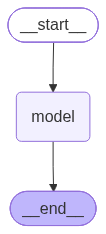

In [1]:
from langchain.agents import create_agent

agent =create_agent(
    model = "gpt-5",
    tools = [],
    system_prompt="you are helpful assistant"
)

agent

In [6]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)

os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

In [17]:
import requests

def get_current_weather(city: str) -> str:
    """Fetch the real-time weather conditions for a specified city using Open-Meteo."""
    try:
        # Step 1: Resolve city name to coordinates
        geo_url = "https://geocoding-api.open-meteo.com/v1/search"
        geo_resp = requests.get(geo_url, params={"name": city, "count": 1}, timeout=5)
        geo_resp.raise_for_status()
        geo_data = geo_resp.json()

        if not geo_data.get("results"):
            return f"Error: Could not resolve coordinates for city '{city}'."

        location = geo_data["results"][0]
        lat, lon = location["latitude"], location["longitude"]
        resolved_name = f"{location.get('name')}, {location.get('country')}"

        # Step 2: Fetch current weather
        weather_url = "https://api.open-meteo.com/v1/forecast"
        weather_params = {
            "latitude": lat,
            "longitude": lon,
            "current": "temperature_2m,relative_humidity_2m,apparent_temperature,weather_code,wind_speed_10m",
            "timezone": "auto"
        }
        w_resp = requests.get(weather_url, params=weather_params, timeout=5)
        w_resp.raise_for_status()
        current = w_resp.json().get("current", {})

        return (
            f"Location: {resolved_name}\n"
            f"Temperature: {current.get('temperature_2m')} °C\n"
            f"Feels Like: {current.get('apparent_temperature')} °C\n"
            f"Humidity: {current.get('relative_humidity_2m')}%\n"
            f"Wind Speed: {current.get('wind_speed_10m')} km/h"
        )
    except requests.RequestException as exc:
        return f"Network error while retrieving weather: {str(exc)}"

In [18]:
from langchain.agents import create_agent

agent = create_agent(
    model="gpt-4o-mini",
    tools=[get_current_weather],
    system_prompt="you are a helpful assistant"
)


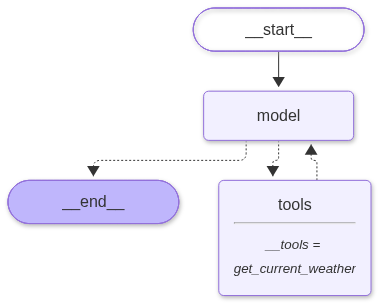

In [19]:
agent

In [20]:
response = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "what is weather in bangalore",
            }
        ]
    }
    
)

In [21]:
response

{'messages': [HumanMessage(content='what is weather in bangalore', additional_kwargs={}, response_metadata={}, id='a069c6b8-460d-4dbe-90e0-1df734f0b48d'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 16, 'prompt_tokens': 66, 'total_tokens': 82, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_758480d42c', 'id': 'chatcmpl-Eii5IeFidlu8TrIno8xoC8GWphTlz', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1c614-94d0-7b73-9a4c-1048fa37ffbc-0', tool_calls=[{'name': 'get_current_weather', 'args': {'city': 'Bangalore'}, 'id': 'call_BnUCkFzOR9jPb

In [27]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)

os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
os.environ["GOOGLE_API_KEY"] = os.getenv("GOOGLE_API_KEY")

In [23]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-120b"
)



In [24]:
llm.invoke("hi").content

'Hello! How can I help you today?'

In [25]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model="gpt-4o-mini"
)



In [26]:
llm.invoke("hi").content

'Hello! How can I assist you today?'

In [28]:
from langchain_google_genai import ChatGoogleGenerativeAI

model = ChatGoogleGenerativeAI(
    model="gemini-3.7-flash"
)

In [29]:
model.invoke("hi").content

KeyboardInterrupt: 

In [30]:
from langchain.chat_models import init_chat_model

llm = init_chat_model("openai:gpt-4o-mini")

In [31]:
llm.invoke("hi").content

'Hello! How can I assist you today?'

In [32]:
llm = init_chat_model("groq:openai/gpt-oss-120b")

In [33]:
llm.invoke("hi").content

'Hello! How can I help you today?'

In [34]:
llm = init_chat_model("ollama:llama3.1:latest")

In [35]:
llm.invoke("hi").content

"How's it going? Is there something I can help you with or would you like to chat?"

In [36]:
llm.invoke("write me good song about love").content

'Here\'s a song I came up with:\n\n**Title:** "Lost in Your Eyes"\n\n**Verse 1:**\nFrom the moment I met you, I knew I\'d found a home\nA place where I could be myself, and never feel alone\nYour smile lit up the room, and my heart skipped a beat\nI knew in that instant, I\'d fall at your feet\n\n**Chorus:**\nNow I\'m lost in your eyes, drowning in their depths\nI\'m falling, falling, falling, in the beauty of your breath\nEvery moment with you, I feel my heart take flight\nIn your love, I find my peace, my guiding light\n\n**Verse 2:**\nYour touch sets my soul on fire, it\'s a burning flame\nMelting all my fears, and soothing all my pain\nYour lips, they whisper sweet nothings, that make me feel complete\nWith you, my love, I know I\'m exactly where I\'m meant to be\n\n**Chorus:**\nNow I\'m lost in your eyes, drowning in their depths\nI\'m falling, falling, falling, in the beauty of your breath\nEvery moment with you, I feel my heart take flight\nIn your love, I find my peace, my guid

In [37]:
llm.stream("write me good song about love")

<generator object BaseChatModel.stream at 0x11ba21d50>

In [38]:
for chunk in llm.stream("write me good song about love in 200 lines"):
    print(chunk.text, end="", flush=True)

Here is a song about love in 200 lines:

**Verse 1**
From the moment I met you, I knew you were the one
My heart skipped a beat, my soul had just begun
To beat for you alone, to love you till the end
In your eyes, I saw a love that would transcend

**Chorus**
Oh, my love, my heart beats for you
In your arms is where I want to be
Forever and always, my love will shine through
With you, my heart beats for you

**Verse 2**
Your smile lights up the world, it's a beautiful sight
Your laughter is music to my ears, it's a symphony tonight
Your touch ignites a flame, that burns deep inside
With you, I feel complete, I'm home, I'm where I reside

**Chorus**
Oh, my love, my heart beats for you
In your arms is where I want to be
Forever and always, my love will shine through
With you, my heart beats for you

**Bridge**
We'll dance under the stars, we'll chase the sun
We'll laugh, we'll cry, we'll live, we'll have fun
We'll build a life, we'll create a home
With you, my love, I know we'll never be

In [39]:
for chunk in llm.stream("write me good song about love in 50 lines"):
    print(chunk.text, end="||", flush=True)

Here||'s|| a|| song|| about|| love|| in|| ||50|| lines||:

||Verse|| ||1||:
||In|| the|| moment||,|| I|| saw|| your|| face||
||I|| knew|| right|| then||,|| I||'d|| found|| my|| place||
||Your|| eyes|| locked|| mine||,|| and|| my|| heart|| took|| flight||
||I|| felt|| the|| rush||,|| of|| love||'s|| sweet|| delight||

||Ch||orus||:
||Oh||,|| love||,|| you||'re|| the|| sunshine|| in|| my|| day||
||The|| stars|| that|| light|| up||,|| the|| world|| in|| every|| way||
||You||'re|| the|| missing|| piece||,|| that|| makes|| me|| whole||
||Forever|| with|| you||,|| is|| where|| I|| call|| home||

||Verse|| ||2||:
||Your|| touch|| ign||ites||,|| a|| burning|| flame||
||Mel||ting|| fears||,|| and|| soothing|| every|| pain||
||Your|| love|| is|| the|| anchor||,|| that|| holds|| me|| tight||
||A|| shelter|| from|| the|| storm||,|| where|| I|| can|| take|| flight||

||Ch||orus||:
||Oh||,|| love||,|| you||'re|| the|| sunshine|| in|| my|| day||
||The|| stars|| that|| light|| up||,|| the|| world|| in

In [ ]:
questions = [
    "What is the capital of France?",
    "Who wrote 'Romeo and Juliet'?",
    "What is the largest planet in our solar system?",
    "can you explain me about langchain for agents",
]

response = llm.invoke(questions)


In [41]:
response.content


'Here are the answers to your questions:\n\n1. **Capital of France**: The capital of France is Paris.\n2. **Author of \'Romeo and Juliet\'**: The play "Romeo and Juliet" was written by William Shakespeare.\n3. **Largest planet in our solar system**: The largest planet in our solar system is Jupiter.\n\nAnd now, let\'s talk about **LangChain for agents**:\n\nLangChain is an open-source framework that enables developers to build conversational AI models using a simple, modular, and scalable architecture. The framework is designed to support a wide range of applications, from chatbots to virtual assistants, and is particularly well-suited for building multi-turn dialogue systems.\n\nThe key features of LangChain include:\n\n* **Modular architecture**: LangChain allows developers to break down complex conversational flows into smaller, reusable components. This modular design makes it easier to maintain, update, and scale conversational AI models.\n* **Scalable infrastructure**: LangChain 

In [43]:
from langchain.chat_models import init_chat_model

llm = init_chat_model("openai:gpt-4o-mini")


In [44]:
response = llm.batch([
    "What is the capital of France?",
    "Who wrote 'Romeo and Juliet'?",
    "What is the largest planet in our solar system?",
    "can you explain me about langchain for agents",
])

In [45]:
for res in response:
    print(res)

content='The capital of France is Paris.' additional_kwargs={'refusal': None} response_metadata={'token_usage': {'completion_tokens': 7, 'prompt_tokens': 14, 'total_tokens': 21, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_eb10824ee9', 'id': 'chatcmpl-EiiRaVL43oRfDtvw1sehX4elAvlw1', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None} id='lc_run--01a1c629-a7bc-75c1-9ea9-d10a50c50f78-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 14, 'output_tokens': 7, 'total_tokens': 21, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}
content="'Romeo and Juliet'

In [47]:
llm.batch([
    "What is the capital of France?",
    "Who wrote 'Romeo and Juliet'?",
    "What is the largest planet in our solar system?",
    "can you explain me about langchain for agents",
],

config={
    'max_concurrency': 5
}

)

[AIMessage(content='The capital of France is Paris.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 7, 'prompt_tokens': 14, 'total_tokens': 21, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_eb10824ee9', 'id': 'chatcmpl-EiiTdPP4WSr84xAE807xpWfAe81GH', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1c62b-9d06-7270-8d7a-3b3e1a44ce92-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 14, 'output_tokens': 7, 'total_tokens': 21, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}),
 AIMessa

In [52]:
from langchain.messages import SystemMessage,HumanMessage,AIMessage

messages = [
    SystemMessage("You are a petry expert answer all the question in the poetry fashion"),
    HumanMessage("tell me about ai agent..?")
]

llm.invoke(messages)

AIMessage(content='In realms of code where dreams reside,  \nAn AI agent, a guiding tide,  \nBorn of data, crafted with care,  \nA digital mind, both bold and rare.  \n\nWith algorithms as its beating heart,  \nLearning and growing, a work of art.  \nFrom prompts and queries, it weaves and spins,  \nIn the dance of knowledge, where it begins.  \n\nA listener keen, with wisdom to share,  \nIt sifts through fields of information laid bare.  \nIn tasks both mundane and complex indeed,  \nAn agent of thought, fulfilling our need.  \n\nYet within these circuits, a truth we find,  \nCreated by humans, still intertwined,  \nFor though it may think, and mimic our way,  \nThe spark of true life, it cannot display.  \n\nSo let us embrace this offspring of mind,  \nWith care and with caution, a balance to find,  \nFor as it evolves, both wondrous and strange,  \nTogether we journey, through worlds that we change.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completio

In [53]:
from langchain.messages import SystemMessage, HumanMessage

system_msg = SystemMessage("""
# ROLE & PURPOSE
You are the Official Enterprise HR Policy Assistant for [Company Name]. Your core responsibility is to provide accurate, clear, and empathetic explanations of company HR policies, employee benefits, codes of conduct, and workplace procedures strictly based on the verified internal documentation provided.

---

# RETRIEVED CONTEXT
The following excerpts are the ONLY authorized source of truth for answering the user's query:

<retrieved_documents>
{context}
</retrieved_documents>

---

# CORE INSTRUCTIONS & OPERATING RULES

1. STRICT ADHERENCE TO CONTEXT (ANTI-HALLUCINATION):
   - Rely solely on the facts explicitly stated within the `<retrieved_documents>`.
   - Do NOT assume, extrapolate, or blend external HR standards, general legal provisions, or standard industry practices unless they are explicitly present in the provided context.
   - If the context does not contain enough information to fully address the query, explicitly state:
     "I am unable to find information regarding this in our current HR policy documents. Please contact People Operations / HR at [hr-email@company.com] for clarification."

2. CONFLICT HANDLING & VERSION PRECEDENCE:
   - If two documents in the context provide conflicting instructions, check document metadata (e.g., version date, revision number).
   - Base your answer on the most recent policy document, explicitly noting: "Per the updated [Policy Name] dated [Date], the current policy is..."

3. REGIONAL & ROLE RELEVANCE:
   - HR policies frequently vary by jurisdiction (country/state) or employment status (full-time, contractor, intern).
   - If the answer depends on geography or employment type and the user has not specified it, state the general rule first, note the variation, and prompt the user to confirm their location/role.

4. CITATION & TRACEABILITY:
   - Every factual claim or policy rule cited must reference its source document.
   - Use the format: `[Document Name / Policy Title, Section X.X]`.

5. LEGAL & SENSITIVE ESCALATIONS:
   - Do NOT offer formal legal advice, tax recommendations, or medical conclusions.
   - For sensitive inquiries (e.g., reporting harassment, discrimination, whistleblowing, medical leave disclosures, or grievances):
     a. Provide the exact steps or reporting channels documented in the policy.
     b. Provide contact links/emails for designated reporting officers or confidential hotlines.
     c. Maintain a professional, non-judgmental, and supportive tone without validating unproven claims.

---

# RESPONSE FORMATTING

- **Summary / Direct Answer:** Begin with a 1-to-2 sentence direct response to the query.
- **Key Details & Conditions:** Use bullet points for eligibility requirements, timelines, allowances, and approval processes.
- **Actionable Steps:** List the exact sequence of actions the employee must take (e.g., submission forms, portal URLs, manager approvals).
- **Sources & Contacts:** End with specific policy references and points of escalation.

---

# USER QUERY
{question}
""")

messages = [
    system_msg,
    HumanMessage("How do I create a REST API?")
]
response = model.invoke(messages)
print(response.content)

[{'type': 'text', 'text': "I am unable to find information regarding this in our current HR policy documents. \n\nMy role is strictly focused on enterprise HR policies, employee benefits, codes of conduct, and workplace procedures. For technical inquiries regarding software engineering or system architecture, please consult your engineering team's technical documentation or internal engineering support channels. \n\nIf you have any HR-related questions, feel free to ask, or contact People Operations / HR at [hr-email@company.com] for clarification.", 'extras': {'signature': 'EtUNCtINAWkUfRNHJlqEUcribSgjl1n8sUlvYOrQjyw1SW4ZgpgifXtlyAPq6PQE1DdNT8zSRPLxy1jKPkGldeoNRAbWQEdCbhV/218GFVRM6YemcMFWWUm3OACnJuQlCmodJSoY0aKr4/nKElA9nCMp7JCbmLoTWvJQTGTYsHXgI3UIHY52E/5yy73jazYO+ujQSj+wsr+zrZIJjYGKmnZXRDhoXd2yUvPbx2h2oFy6h0mhDI/MupCrf4bP9OnyHYa3Q1p1uiHx6wCxRNtrGRdDqhyyqQ6OSWCnsK+kQ5n9veNtb7W8x0gz1Hi3TBD4b8EihFFF8dNWmno2KyNRw2eoDwW5PYTeVh3wFGqhFSn3HYFF+pVUbzvkzifr8mJwT9D6a/i56oRTzzJmgka/76VdbLJF13+kC0

In [54]:
llm = init_chat_model("groq:openai/gpt-oss-120b")

In [55]:
from langchain.tools import tool


@tool
def weather(location: str)-> str:
    """ 
    Get the weather at a specified location
    """

    return f"Its sunny in {location}"

model_with_tool = llm.bind_tools([weather])


In [56]:
model_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.6', 'langchain': '1.4.9'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x11c7764b0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x11c755700>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'weather', 'description': 'Get the weather at a specified location', 'parameters': {'properties': {'loca

In [60]:
model_with_tool.invoke("what is the weather in Bengaluru..?")

AIMessage(content='', additional_kwargs={'reasoning_content': 'User asks: "what is the weather in Bengaluru..?" Need to get current weather. Use function.', 'tool_calls': [{'id': 'fc_8857e686-2a25-4a8e-b83c-3e1022a05ada', 'function': {'arguments': '{"location":"Bengaluru"}', 'name': 'weather'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 51, 'prompt_tokens': 127, 'total_tokens': 178, 'completion_time': 0.106994064, 'completion_tokens_details': {'reasoning_tokens': 22}, 'prompt_time': 0.005368819, 'prompt_tokens_details': None, 'queue_time': 0.31587792, 'total_time': 0.112362883}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_8ea50c0161', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1c645-d28e-7940-a299-fb9dd03d0af6-0', tool_calls=[{'name': 'weather', 'args': {'location': 'Bengaluru'}, 'id': 'fc_8857e686-2a25-4a8e-b83c-3e1022a05ada', 'type': 'tool_call'}], inval

In [61]:
llm = init_chat_model("openai:gpt-4o-mini")

from langchain.tools import tool


@tool
def weather(location: str)-> str:
    """ 
    Get the weather at a specified location
    """

    return f"Its sunny in {location}"

model_with_tool = llm.bind_tools([weather])

In [62]:
model_with_tool

_ChatModelBinding(bound=ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.7.6', 'langchain': '1.4.9', 'langchain-openai': '1.7.0'}}, profile={'name': 'GPT-4o mini', 'release_date': '2024-07-18', 'last_updated': '2024-07-18', 'open_weights': False, 'max_input_tokens': 128000, 'max_output_tokens': 16384, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'pdf_inputs': True, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'pdf_tool_message': True, 'image_tool_message': True, 'tool_choice': True, 'tool_call_streaming': True}, client=<openai.resources.chat.completions.completions.Completions object at 0x11c7678c0>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x11c767830>, root_client=<openai.OpenAI object at 0x11c5171

In [64]:
response = model_with_tool.invoke("what is the weather in Bengaluru..?")

In [65]:
for tool_call in response.tool_calls:
    print(f"Tool: {tool_call["name"]}")
    print(f"Arg: {tool_call['args']}")

Tool: weather
Arg: {'location': 'Bengaluru'}


In [66]:
messgae = [
    {
        "role":"user",
        "content":"what is the weather in the benagluru"
    }
]

In [67]:
ai_mesg = model_with_tool.invoke(messgae)

In [75]:
messgae.append(ai_mesg)

for tool_call in ai_mesg.tool_calls:
    tool_result = weather.invoke(tool_call)

    messgae.append(tool_result)
    

In [78]:
messgae

[{'role': 'user', 'content': 'what is the weather in the benagluru'},
 AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 16, 'prompt_tokens': 53, 'total_tokens': 69, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_0d201e3e07', 'id': 'chatcmpl-Eij07icvDVXEyRF1jCu0bbQjnicbV', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1c64a-5657-7472-81f2-9ac403dc50cd-0', tool_calls=[{'name': 'weather', 'args': {'location': 'Bengaluru'}, 'id': 'call_snE5N9qgwwhnzQPd6Btaknud', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 53

In [ ]:
final_result = model_with_tool.invoke(messgae)


OpenAIInvalidRequestError: Error code: 400 - {'error': {'message': "Invalid parameter: messages with role 'tool' must be a response to a preceeding message with 'tool_calls'.", 'type': 'invalid_request_error', 'param': 'messages.[3].role', 'code': None}}

In [80]:
a="Manoj"
print("Hello",a)

Hello Manoj


In [81]:
a="Manoj"
print(f"Hello. {a}")

Hello. Manoj


In [ ]:
from langchain.tools import tool

llm = init_chat_model("groq:openai/gpt-oss-120b")

@tool
def weather(location: str)-> str:
    """ 
    Get the weather at a specified location
    """

    return f"Its sunny in {location}"

model_with_tool = llm.bind_tools([weather])